# Практическая работа №5

## Классификатор и анализ метрик — Вариант B

**Датасет:** Palmer Penguins

**Цель работы:** обучить модель LogisticRegression для бинарной классификации пингвинов, построить ROC и PR-кривые, исследовать матрицу ошибок и подобрать порог классификации с учётом стоимости ошибок.

**Целевая переменная:** is_gentoo

- 0 — другой вид пингвина.
- 1 — Gentoo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

In [2]:
df = pd.read_csv("../data/penguins.csv")

display(df.head())

print("Размер:", df.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Размер: (344, 7)


In [3]:
df["is_gentoo"] = (df["species"] == "Gentoo").astype(int)

print(df["is_gentoo"].value_counts())

print("\nПроцентное соотношение:")
print(
    (df["is_gentoo"].value_counts(normalize=True) * 100)
    .round(2)
)

is_gentoo
0    220
1    124
Name: count, dtype: int64

Процентное соотношение:
is_gentoo
0    63.95
1    36.05
Name: proportion, dtype: float64


### Постановка задачи

В работе решается задача бинарной классификации: определение принадлежности пингвина к виду Gentoo.

Положительный класс (1) — Gentoo, отрицательный (0) — Adelie или Chinstrap.

Классы распределены неравномерно: около 36% объектов относятся к положительному классу.

Поэтому для оценки качества недостаточно использовать только Accuracy.

In [4]:
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorical_features = ["sex"]

features = numeric_features + categorical_features

X = df[features].copy()
y = df["is_gentoo"]

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (206, 5)
Validation: (69, 5)
Test: (69, 5)


### Разделение данных

Данные разделены на обучающую, валидационную и тестовую выборки.

Train используется для обучения модели, Validation — для выбора порога, Test — для окончательной оценки качества.

Разделение выполнено со стратификацией для сохранения баланса классов.

Признак species исключён из входных данных, поскольку напрямую раскрывает целевую переменную is_gentoo.

In [5]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


### Предобработка и обучение

Для числовых признаков используется SimpleImputer с заполнением медианой и StandardScaler.

Для категориального признака sex пропуски заменяются категорией Unknown, после чего используется OneHotEncoder.

Предобработка и LogisticRegression объединены в один Pipeline.

Все статистики вычисляются только на данных Train, что предотвращает утечку информации.

In [6]:
val_proba = model.predict_proba(X_val)[:, 1]

print("Первые 10 вероятностей:")
print(np.round(val_proba[:10], 3))

Первые 10 вероятностей:
[0.971 0.95  0.974 0.003 0.013 0.    0.982 0.99  0.    0.027]


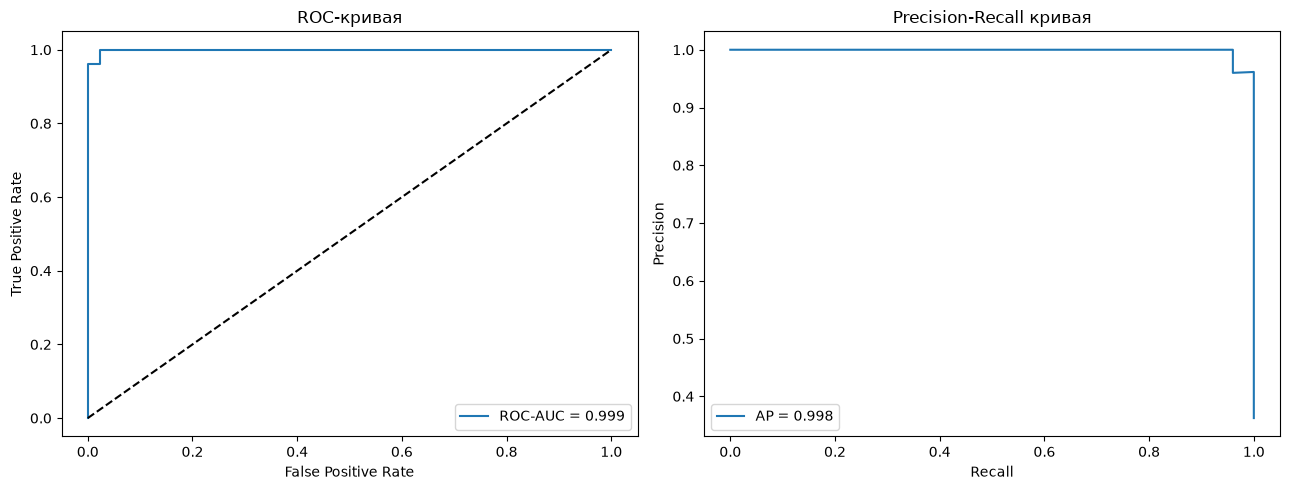

In [7]:
fpr, tpr, _ = roc_curve(y_val, val_proba)
precision, recall, _ = precision_recall_curve(y_val, val_proba)

roc_auc = roc_auc_score(y_val, val_proba)
ap = average_precision_score(y_val, val_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(recall, precision, label=f"AP = {ap:.3f}")
axes[1].set_title("Precision-Recall кривая")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### Анализ ROC и PR-кривых

ROC-кривая показывает соотношение чувствительности и доли ложноположительных результатов при разных порогах.

ROC-AUC характеризует способность модели различать классы. Чем ближе значение к 1, тем лучше модель ранжирует объекты положительного класса выше отрицательных.

PR-кривая показывает связь Precision и Recall.

Average Precision (AP) суммирует качество по PR-кривой и полезна при неравномерном распределении классов.

In [8]:
cost_fp = 1
cost_fn = 4

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []

for threshold in thresholds:
    predictions = (val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = cost_fp * fp + cost_fn * fn
    costs.append(total_cost)

best_threshold = float(thresholds[np.argmin(costs)])

print("Лучший порог:", round(best_threshold, 2))
print("Минимальная стоимость ошибок:", min(costs))

Лучший порог: 0.06
Минимальная стоимость ошибок: 1


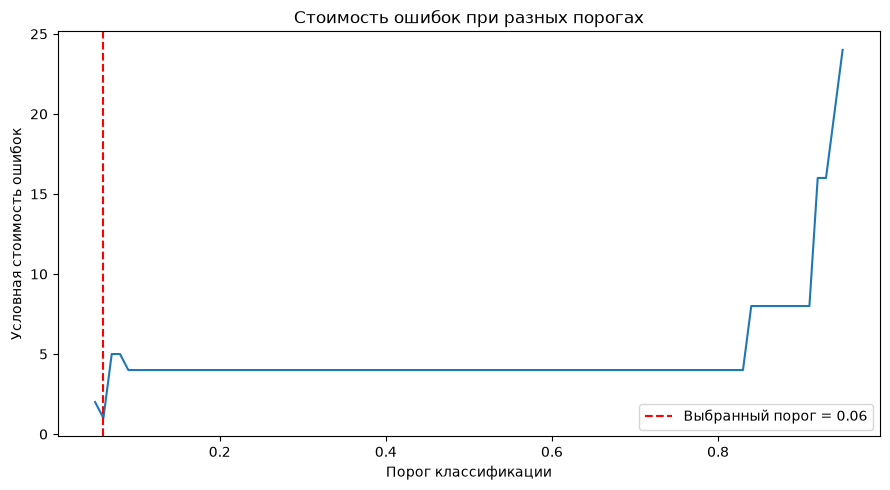

In [9]:
plt.figure(figsize=(9, 5))

plt.plot(thresholds, costs)
plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Выбранный порог = {best_threshold:.2f}"
)

plt.title("Стоимость ошибок при разных порогах")
plt.xlabel("Порог классификации")
plt.ylabel("Условная стоимость ошибок")
plt.legend()
plt.tight_layout()
plt.show()

### Выбор порога классификации

В учебной постановке стоимость ложноотрицательной ошибки FN в четыре раза выше стоимости ложноположительной FP.

Поэтому важно уменьшить число пропущенных объектов класса Gentoo.

Порог подбирается по валидационной выборке на основе минимизации общей стоимости ошибок.

Выбор порога отдельно от тестовой выборки позволяет сохранить независимость итоговой оценки.

In [10]:
model.fit(X_train_full, y_train_full)

test_proba = model.predict_proba(X_test)[:, 1]

def evaluate_threshold(threshold):
    predictions = (test_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost": cost_fp * fp + cost_fn * fn
    }

comparison = pd.DataFrame([
    evaluate_threshold(0.5),
    evaluate_threshold(best_threshold)
])

display(comparison.round(3))

,Threshold,Accuracy,Precision,Recall,F1,FP,FN,Cost
0,0.50,1.000,1.000,1.0,1.000,0,0,0
1,0.06,0.957,0.893,1.0,0.943,3,0,3


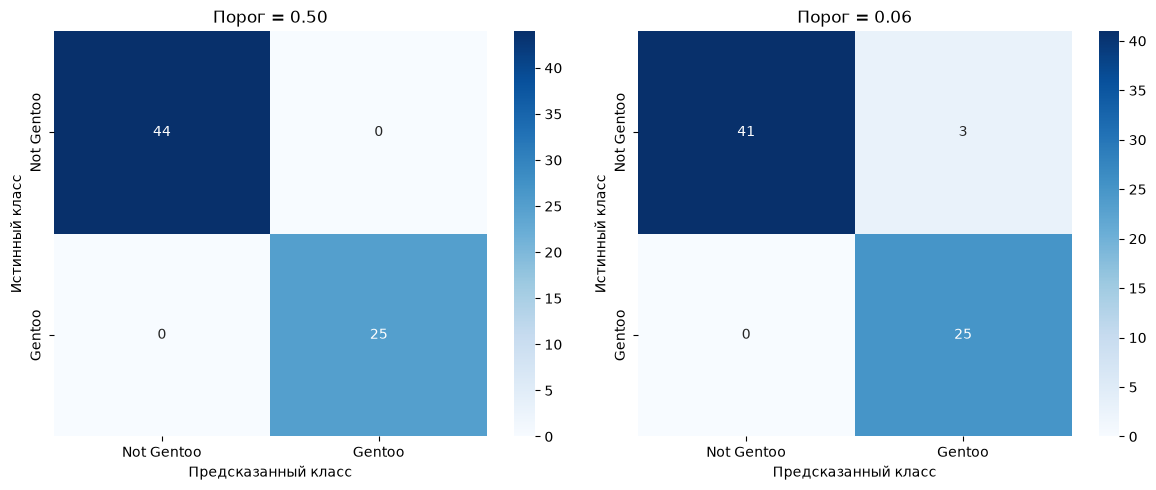

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(
    axes,
    [0.5, best_threshold]
):
    pred = (test_proba >= threshold).astype(int)

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Gentoo", "Gentoo"],
        yticklabels=["Not Gentoo", "Gentoo"],
        ax=ax
    )

    ax.set_title(f"Порог = {threshold:.2f}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()

### Анализ матрицы ошибок

Матрица ошибок показывает количество правильных и неправильных предсказаний по каждому классу.

Особое внимание уделяется FN — случаям, когда настоящий Gentoo не распознан моделью.

Уменьшение порога обычно повышает Recall, но может увеличить количество FP и снизить Precision.

Поэтому важно сравнивать не только Accuracy, но и Precision, Recall, F1 и условную стоимость ошибок.

In [12]:
test_roc_auc = roc_auc_score(y_test, test_proba)
test_ap = average_precision_score(y_test, test_proba)

print("Test ROC-AUC:", round(test_roc_auc, 3))
print("Test Average Precision:", round(test_ap, 3))

Test ROC-AUC: 1.0
Test Average Precision: 1.0


## Итоговый отчёт

1. В работе использован датасет Palmer Penguins для бинарной классификации вида Gentoo.

2. Целевая переменная is_gentoo содержит два класса: 0 — другой вид, 1 — Gentoo.

3. Для подготовки данных использован Pipeline с заполнением пропусков, масштабированием и кодированием категориальных признаков.

4. Обучена модель LogisticRegression. Получены вероятности положительного класса с помощью predict_proba().

5. Построены ROC-кривая и PR-кривая. Рассчитаны ROC-AUC и Average Precision.

6. Для учебного анализа принята стоимость FN = 4 и FP = 1. Порог классификации подбирался на валидационной выборке.

7. Проведено сравнение порога 0,5 с выбранным порогом. Рассчитаны Accuracy, Precision, Recall и F1. Построены матрицы ошибок.

### Заключение

Выбор порога классификации позволяет изменять баланс между Precision и Recall.

При более высокой стоимости FN необходимо уделять особое внимание Recall и количеству пропущенных объектов положительного класса.

Окончательное решение о пороге следует принимать на основе фактических метрик и стоимости ошибок.